# Order of accuracy

**Time** (`order_time`, `decks/deckD.athinput`): a spherical shell with kinematic gas and Marshak
walls; the time step is halved four times on a fixed grid. Error = relative L1 difference of
successive levels of $E$, $F_r$, $T$. The successive orders rise (E: ~1.6, 1.6, 1.8)
but do not reach 2 on this ladder; the criterion is on the finest pair: order
$\ge 1.7$, errors within 5 % of the reference.

**Space** (`order_space`, `decks/wave_cart.athinput`): a linear radiation-hydro wave over one
period, N = 16 ... 128 cells, dt following the CFL. Error = L1 difference of each level to the
next finer one (coarsened). Criterion: order of the finest pair $\ge 1.7$.

**Time, stiff exchange** (`order_stiff`, `decks/wave_cart.athinput`): a trapped radiation-acoustic wave
($x = 100$), the time step halved from T/64 to T/512 with strict solves. Same criterion.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
nb.style()
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in ('order_time', 'order_space', 'order_stiff')}

loading the existing run runs/order_time
loading the existing run runs/order_space
loading the existing run runs/order_stiff


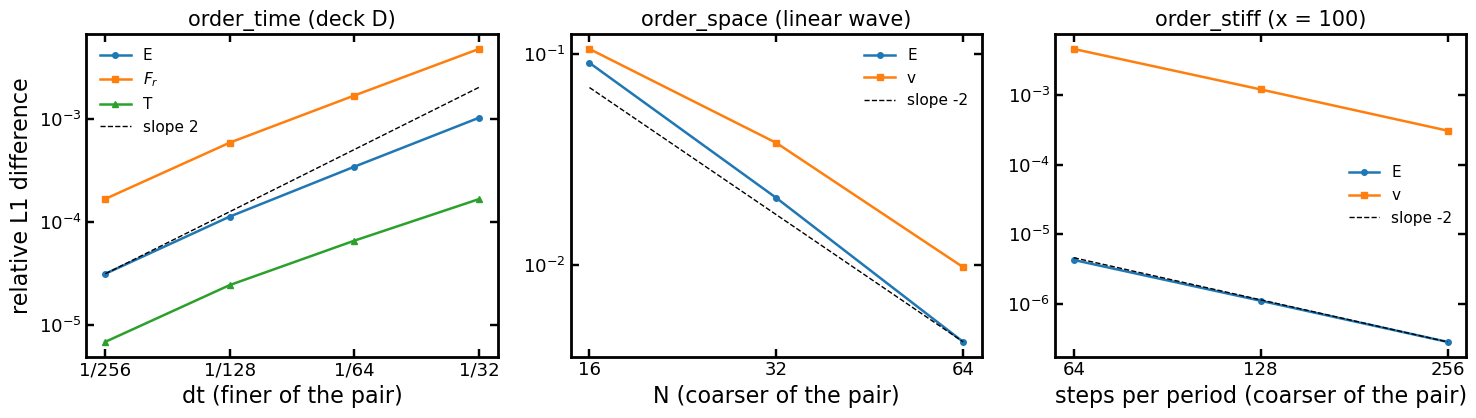

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
dts = np.array([0.0625, 0.03125, 0.015625, 0.0078125, 0.00390625])   # run_tests.t_order_time
r = res['order_time']; x = dts[1:len(r['err_E']) + 1]                # error i: levels i, i + 1
for k, mk in (('E', 'o'), ('F', 's'), ('T', '^')):
    axs[0].loglog(x, r['err_' + k], mk + '-', label=k if k != 'F' else '$F_r$')
axs[0].loglog(x, r['err_E'][-1]*(x/x[-1])**2, 'k--', lw=1, label='slope 2')
axs[0].set(xlabel='dt (finer of the pair)', ylabel='relative L1 difference', title='order_time (deck D)')
ns = np.array([16, 32, 64, 128]); r = res['order_space']; x = ns[:len(r['err_E'])]
for k, mk in (('E', 'o'), ('v', 's')):
    axs[1].loglog(x, r['err_' + k], mk + '-', label=k)
axs[1].loglog(x, r['err_E'][-1]*(x/x[-1])**-2.0, 'k--', lw=1, label='slope -2')
axs[1].set(xlabel='N (coarser of the pair)', title='order_space (linear wave)')
r = res['order_stiff']; x = np.array([64, 128, 256, 512])[:len(r['err_E'])]   # run_tests.t_order_stiff: steps per period
for k, mk in (('E', 'o'), ('v', 's')):
    axs[2].loglog(x, r['err_' + k], mk + '-', label=k)
axs[2].loglog(x, r['err_E'][-1]*(x/x[-1])**-2.0, 'k--', lw=1, label='slope -2')
axs[2].set(xlabel='steps per period (coarser of the pair)', title='order_stiff (x = 100)')
for a, tk in zip(axs, (dts[1:], [16, 32, 64], [64, 128, 256])):
    a.minorticks_off(); a.set_xticks(tk); a.set_xticklabels(['1/%d' % round(1/v) if v < 1 else '%d' % v for v in tk])
    a.legend(fontsize=11)
plt.tight_layout(); plt.show()

In [4]:
for t in res:
    print(t, {k: np.round(v, 3).tolist() for k, v in res[t].items() if k.startswith('order')})
    nb.verdict(t, res[t])

order_time {'order_E': [1.574, 1.605, 1.843], 'order_F': [1.497, 1.517, 1.812], 'order_T': [1.337, 1.428, 1.829]}
PASS order_time   criterion {"last": true, "min": {"order_E": 1.7, "order_F": 1.7, "order_T": 1.7}, "near": {"err_E": [3.15e-05, 0.05], "err_F": [0.000168, 0.05], "err_T": [6.9e-06, 0.05]}}
order_space {'order_E': [2.123, 2.264], 'order_v': [1.477, 1.955]}
PASS order_space   criterion {"last": true, "min": {"order_E": 1.7, "order_v": 1.7}, "near": {"err_E": [0.00436, 0.05], "err_v": [0.00981, 0.05]}}
order_stiff {'order_E': [1.938, 1.955], 'order_v': [1.922, 1.958]}
PASS order_stiff   criterion {"last": true, "min": {"order_E": 1.7, "order_v": 1.7}, "near": {"err_E": [2.9e-07, 0.05], "err_v": [0.000305, 0.05]}}
